In [2]:
# --- Imports ---

import numpy as np
import matplotlib.pyplot as plt
import graphviz
import tensorflow as tf
import tensorflow.keras as keras
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import export_graphviz
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
def plot_samples(xdata, ydata, amount=40):
    for number in range(10):
        indeces = np.random.choice(np.where(ydata == number)[0],size=amount,replace=False)
        fig = plt.figure(figsize=(20,6))
        fig.suptitle("examples for number "+str(number)+":")
        nplt = 1
        for index in indeces:
            ax = fig.add_subplot(4,10,nplt)
            ax.axis('off')
            plt.imshow(xdata[index])
            nplt += 1

In [3]:
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

Pixelwerte werden von 0–255 auf 0–1 skaliert. Das erleichtert den Vergleich mit anderen Modellen.

In [4]:
# Normalisierung
x_train = x_train / 255.0
x_test = x_test / 255.0

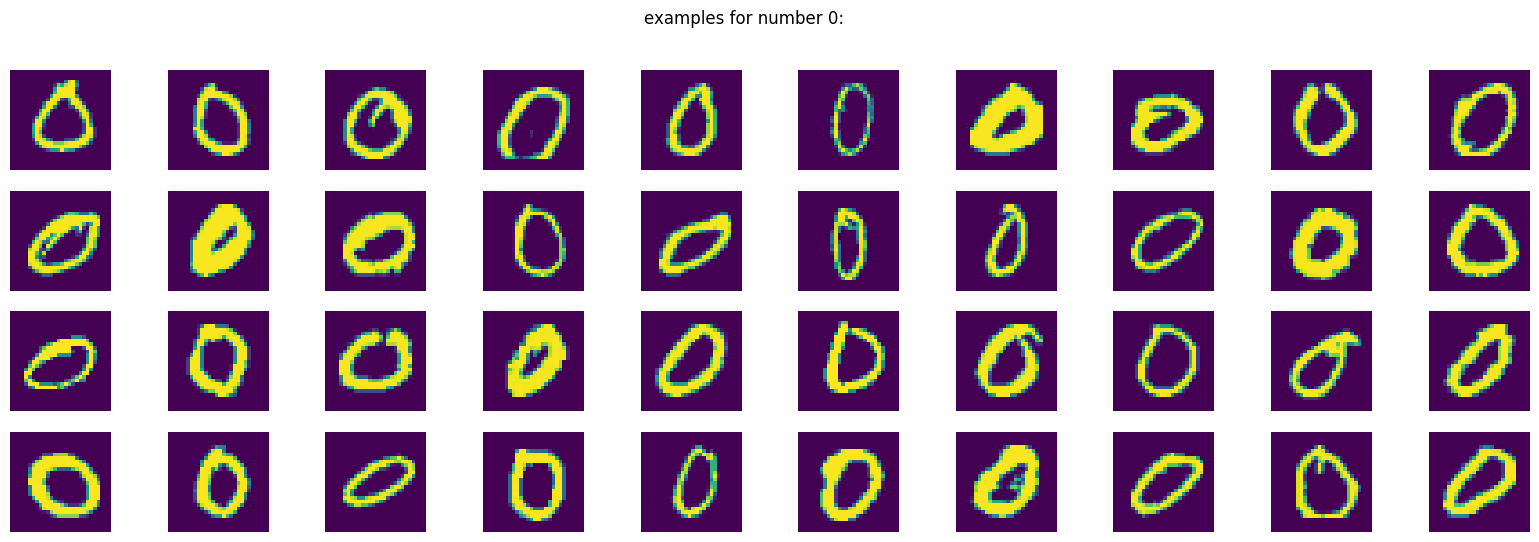

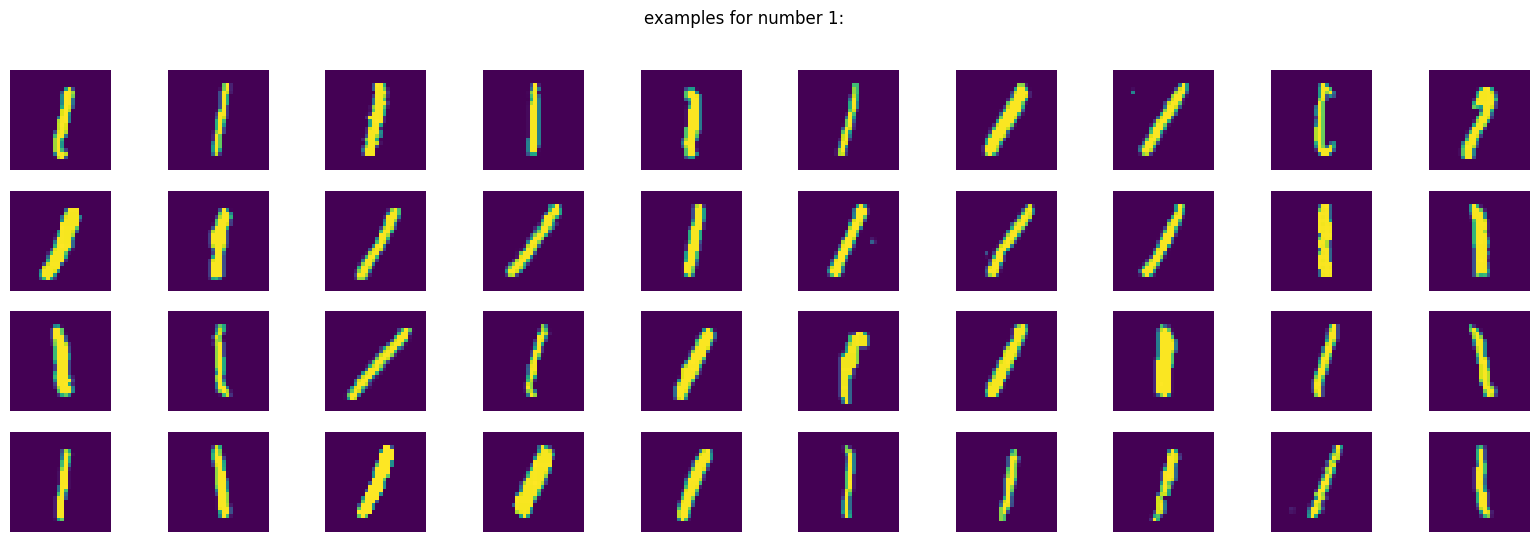

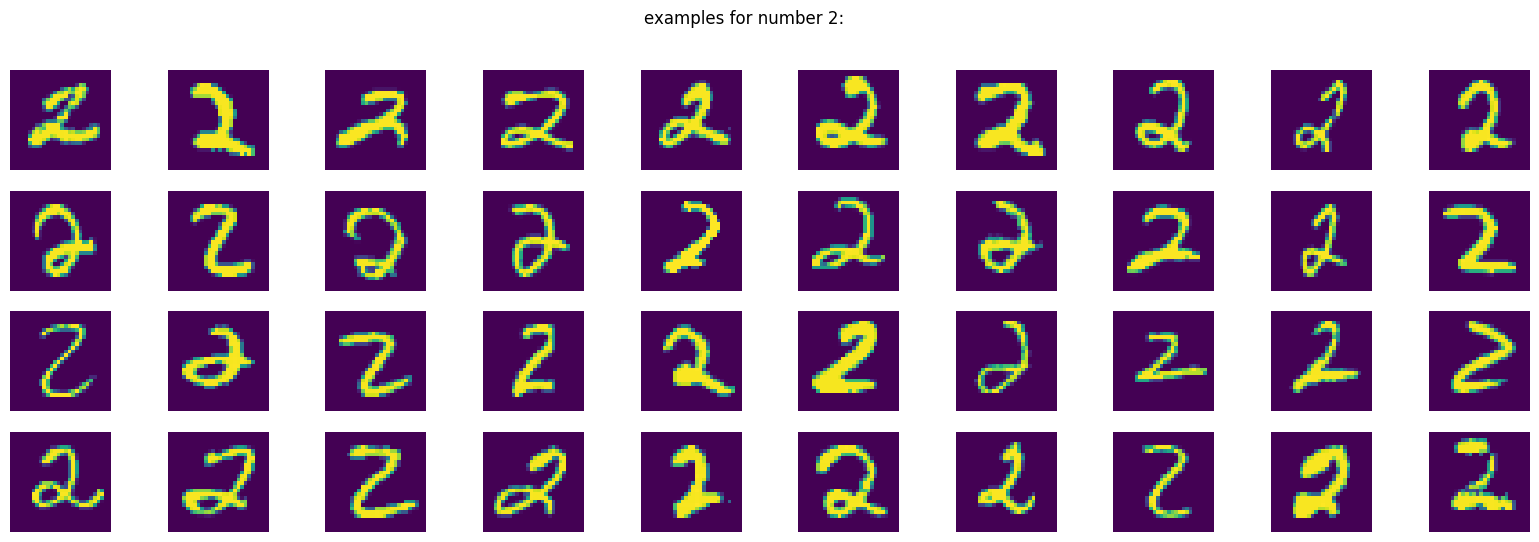

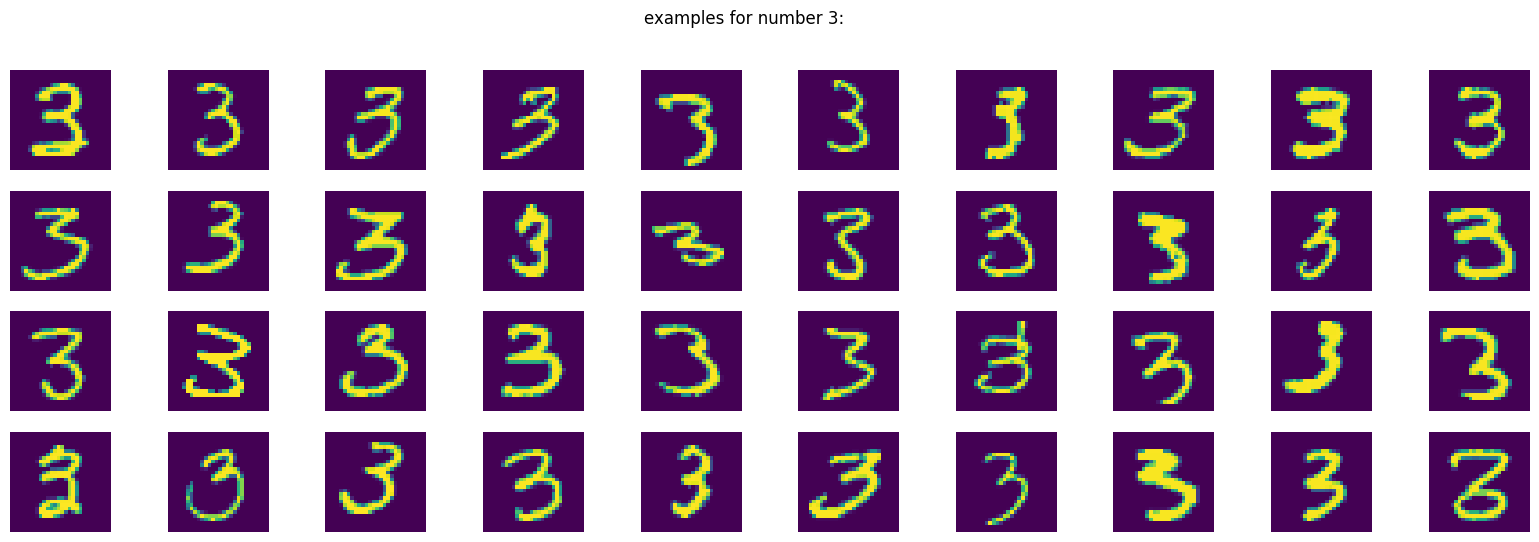

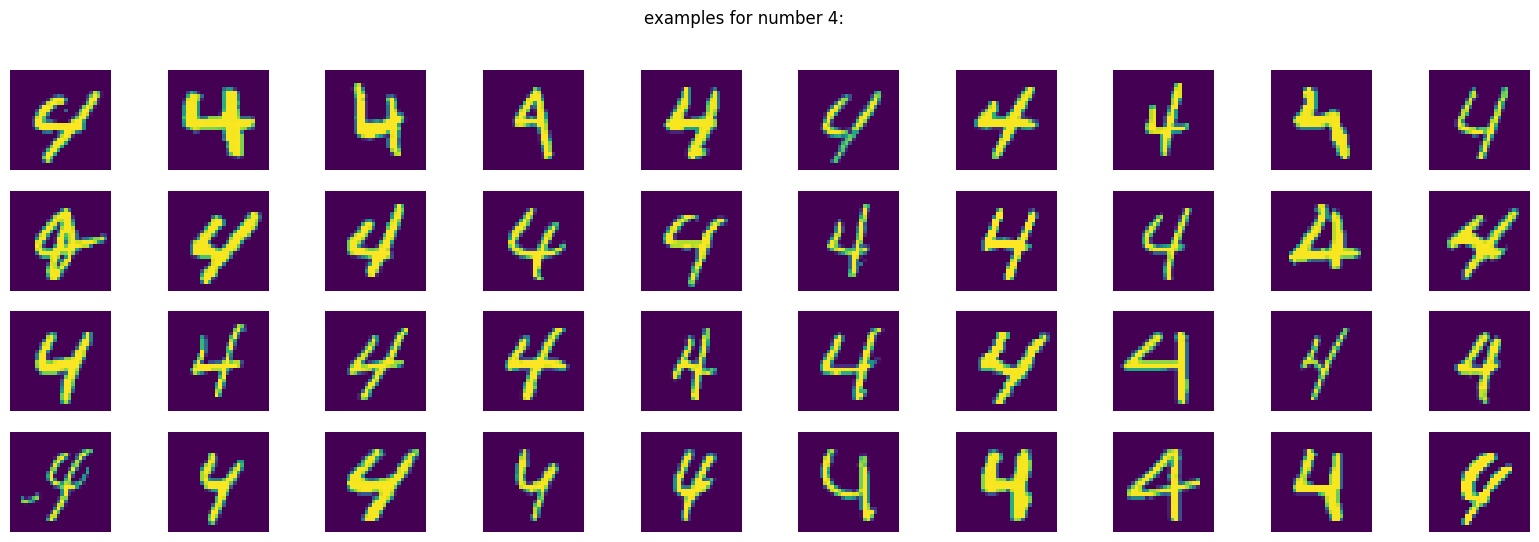

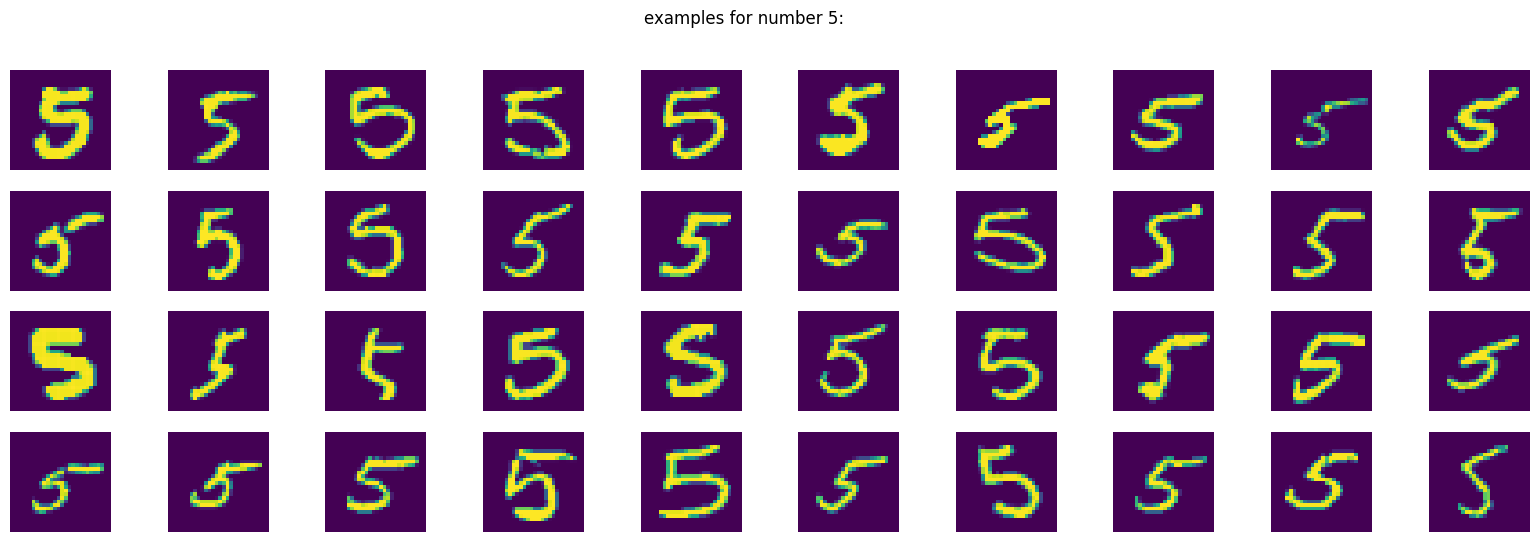

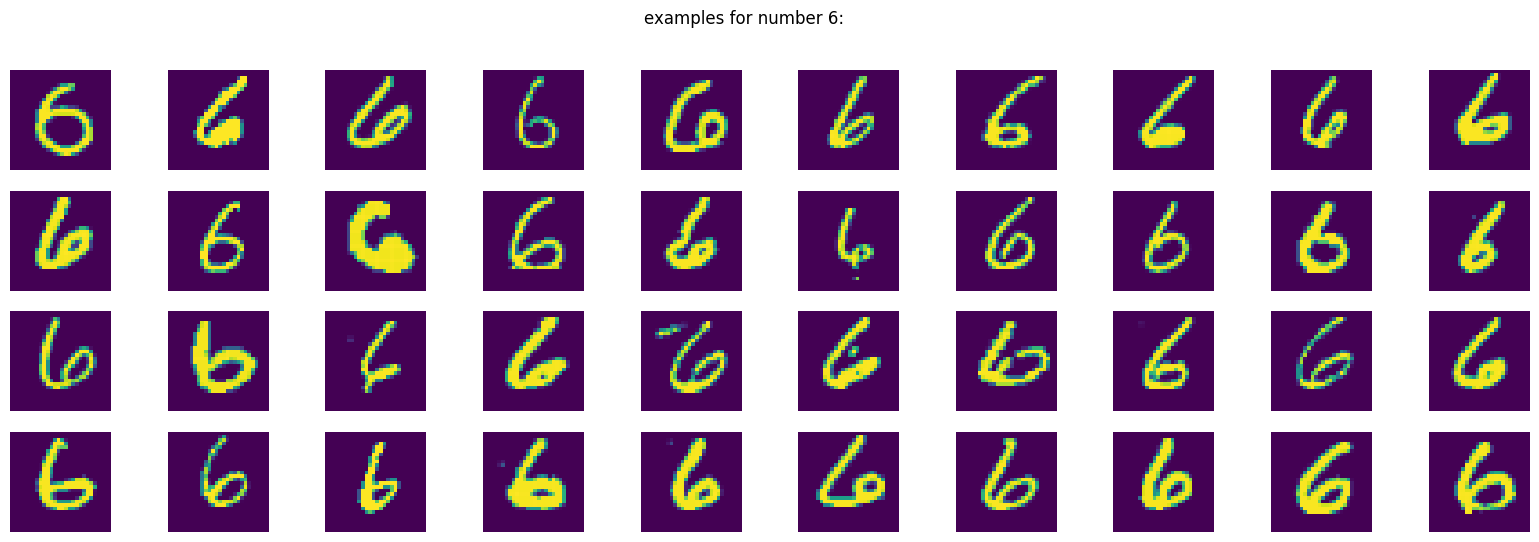

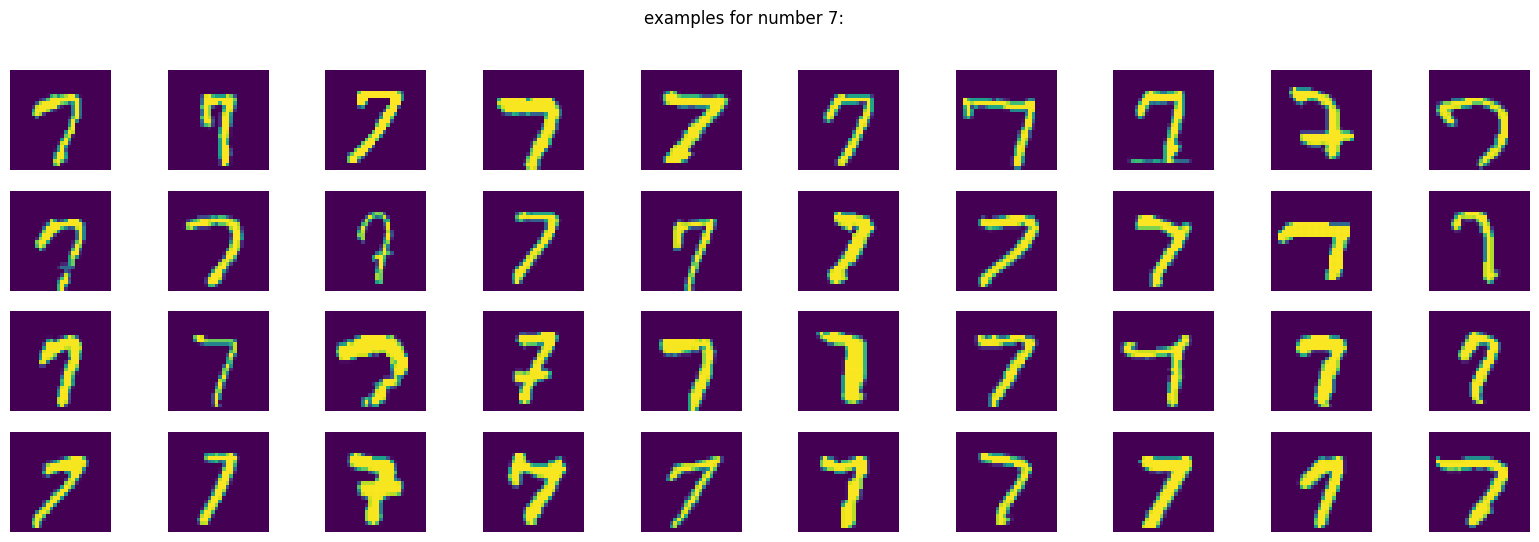

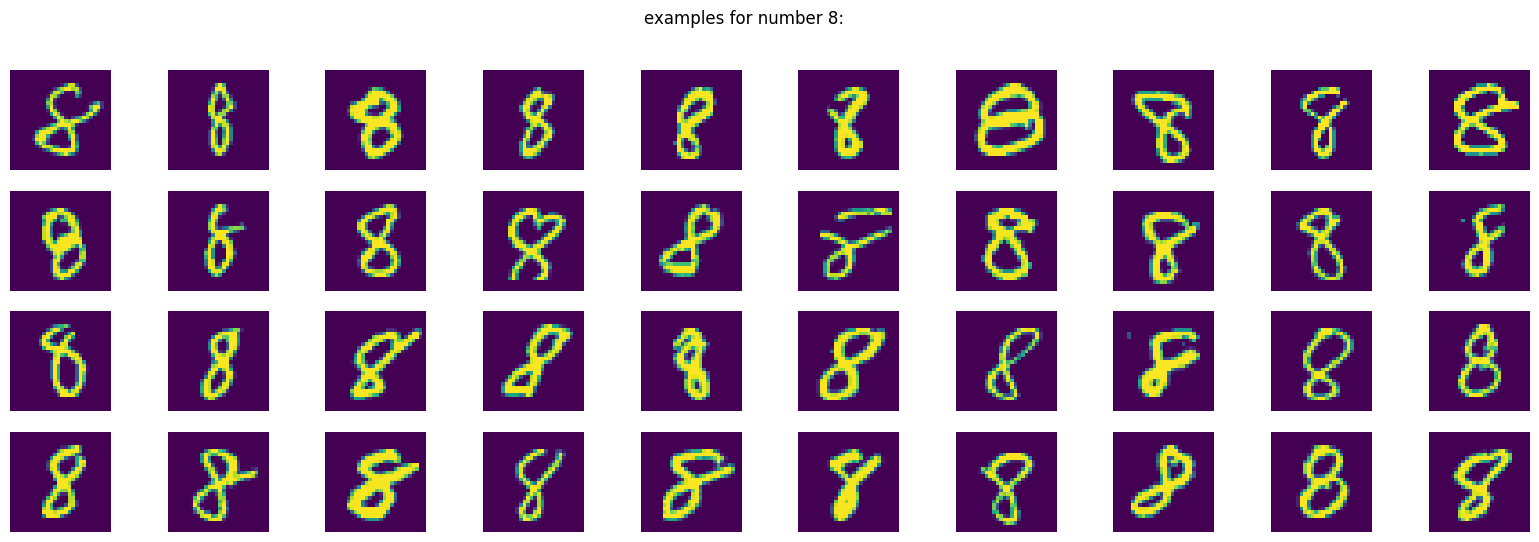

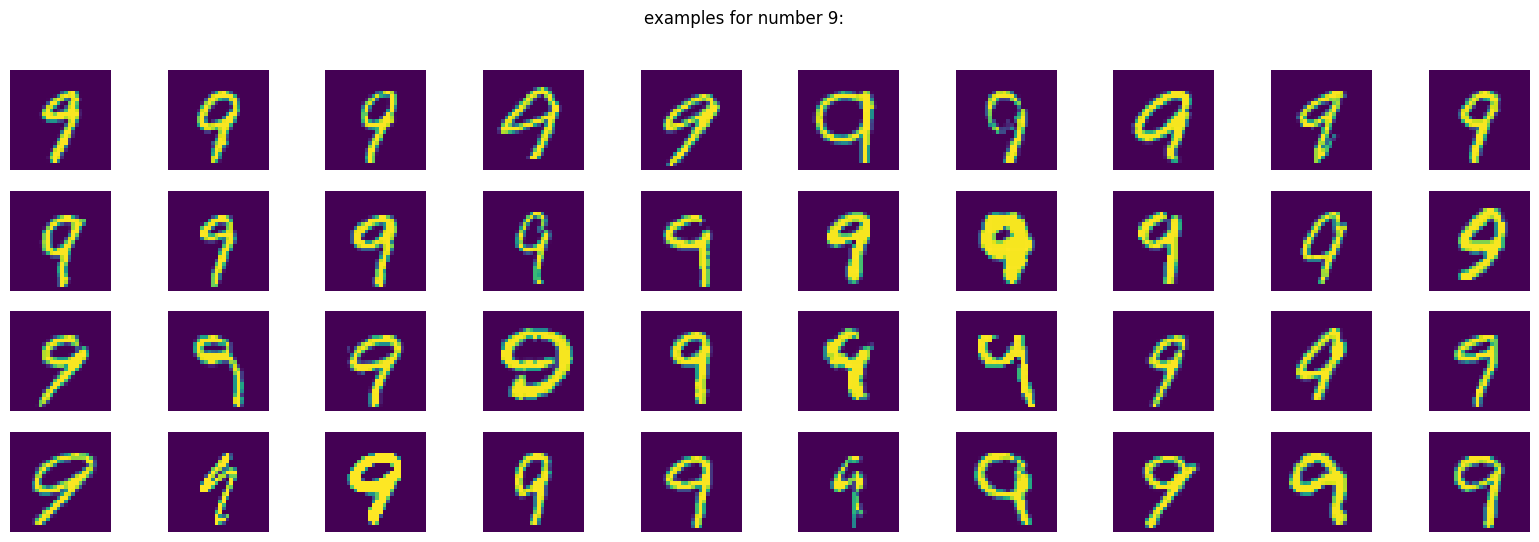

In [8]:
#Ausgabe ein paar Beispiele des Datensatzes
plot_samples(x_train, y_train)

Ein DecisionTreeClassifier erwartet Daten der Form (n_samples, n_features), x_train bei MNIST hat dagegen die Form (60000, 28, 28).

In [5]:
# Ausgabe des Formats des Datensatzes
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)


Umformung der Trainings- und Testdaten in 2D:

In [5]:
# Umwandeln des Datensatzes von 3D in 2D
X_train = x_train.reshape(60000, 28*28)
X_test = x_test.reshape(10000, 28*28)

Beste Tiefe für den Baum bestimmen (Dauer ca. 17 min):

In [11]:
# Kreuzvalidierung zur Ermittlung der Baumtiefe
depths = range(1, 21)
mean_scores = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for depth in depths:
    clf = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    scores = cross_val_score(
        clf,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    mean_scores.append(scores.mean())
    print(f"max_depth={depth}: CV-Accuracy={scores.mean():.4f}")


max_depth=1: CV-Accuracy=0.1970
max_depth=2: CV-Accuracy=0.3392
max_depth=3: CV-Accuracy=0.4718
max_depth=4: CV-Accuracy=0.5879
max_depth=5: CV-Accuracy=0.6690
max_depth=6: CV-Accuracy=0.7336
max_depth=7: CV-Accuracy=0.7773
max_depth=8: CV-Accuracy=0.8121
max_depth=9: CV-Accuracy=0.8381
max_depth=10: CV-Accuracy=0.8558
max_depth=11: CV-Accuracy=0.8633
max_depth=12: CV-Accuracy=0.8677
max_depth=13: CV-Accuracy=0.8716
max_depth=14: CV-Accuracy=0.8736
max_depth=15: CV-Accuracy=0.8714
max_depth=16: CV-Accuracy=0.8715
max_depth=17: CV-Accuracy=0.8714
max_depth=18: CV-Accuracy=0.8712
max_depth=19: CV-Accuracy=0.8712
max_depth=20: CV-Accuracy=0.8722


 (ca. 13 min dann abbruch)

In [ ]:
# Kreuzvalidierung zur Ermittlung von min_samples_leaf
best_depth = 14
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for leaf in range(1, 21):
    clf = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=leaf,
        random_state=42
    )
    scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring="accuracy")
    print(leaf, scores.mean())

1 0.8736499999999999
2 0.8699999999999999
3 0.8713833333333334
4 0.8707499999999999
5 0.87155
6 0.8702333333333334
7 0.8695999999999999
8 0.8685
9 0.8666166666666667
10 0.8656666666666666
11 0.8641333333333334
12 0.8632500000000001
13 0.8628166666666667


KeyboardInterrupt: 

In [ ]:
# Vergleich der Split-Kriterien
for crit in ["gini", "entropy"]:
    clf = DecisionTreeClassifier(
        max_depth=14,
        min_samples_leaf= 1,
        criterion=crit,
        random_state=42
    )
    scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring="accuracy")
    print(crit, scores.mean())

gini 0.8736499999999999
entropy 0.8762000000000001


In [ ]:
# Finales Training

final_clf = DecisionTreeClassifier(
    max_depth=14,
    min_samples_leaf=1,
    criterion="entropy",
    random_state=42
)

final_clf.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=14, random_state=42)

Auf dem Testset auswerten:

In [ ]:
# Finale Auswertung auf dem Testset
test_acc = final_clf.score(X_test, y_test)
print("Final Test Accuracy:", test_acc)

Final Test Accuracy: 0.8855


In [ ]:
# Erstellen der Confusion Matrix zur Auswertung

y_pred = final_clf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 911    1    7    6    3   20   10    4    9    9]
 [   0 1101    7    5    2    7    0    3    8    2]
 [  13    4  899   19   13   12   20   23   25    4]
 [   9    8   23  866    1   39    4   17   25   18]
 [   8    6   15    8  847    6   14   13   19   46]
 [  15    5    6   37    6  755   20    3   26   19]
 [  14    3   13    6   20   22  865    4    8    3]
 [   2   11   31   19   12    5    1  928    8   11]
 [  10    5   22   30   28   22   13    8  815   21]
 [   6    4    4   18   36   21    8   21   23  868]]


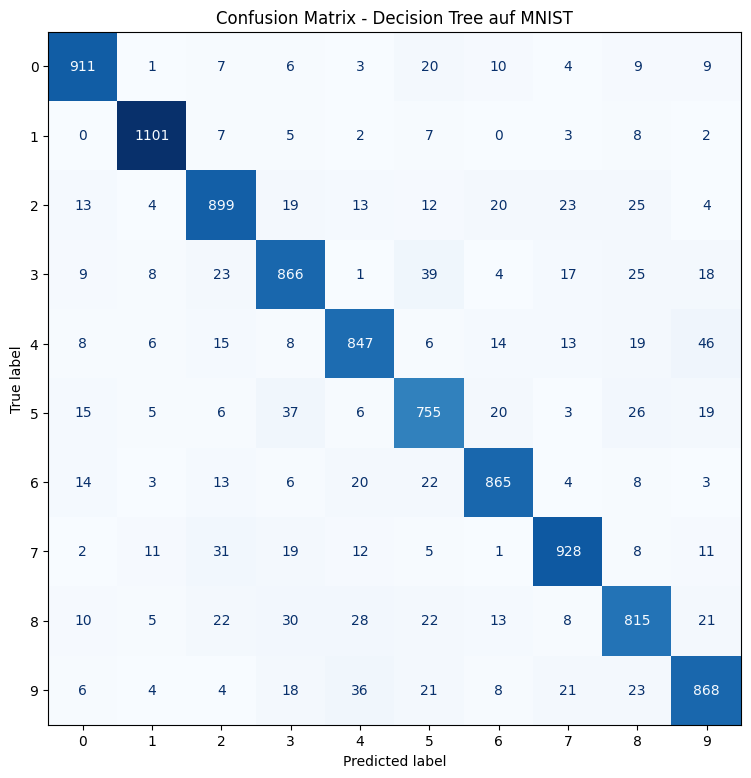

In [ ]:
# Plotten der Confusion Matrix
y_pred = final_clf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[str(i) for i in range(10)])
disp.plot(cmap="Blues", ax=ax, values_format="d", colorbar=False)
plt.title("Confusion Matrix - Decision Tree auf MNIST")
plt.show()

Beobachtung:
- 1, 0 und 7 werden relativ gut erkannt
- 8 ist schwieriger und wird auf mehrere Klassen verteilt fehlklassifiziert
- typische Verwechslungen: 3/5, 4/9

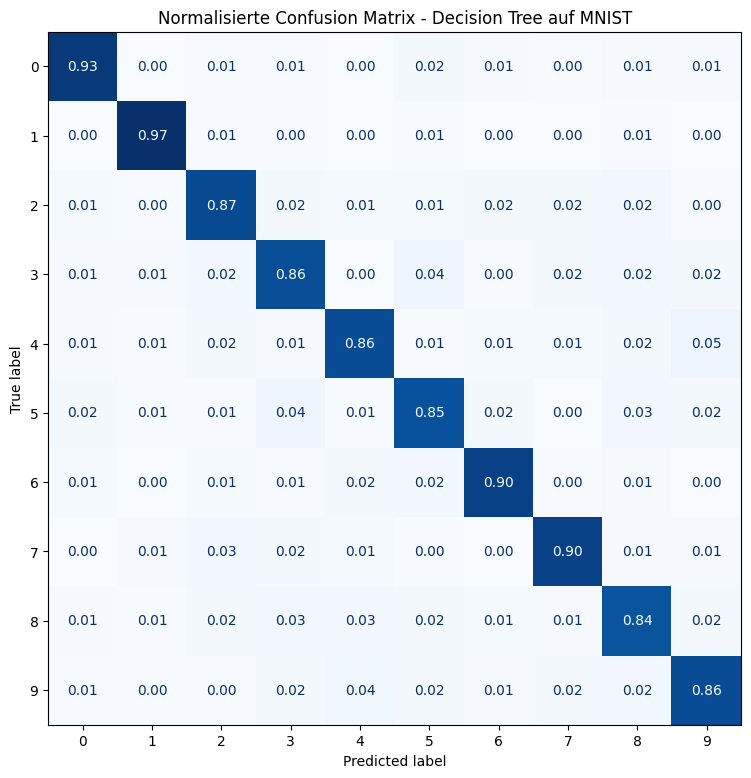

In [ ]:
# Normalisierung der Confusion Matrix

cm_norm = confusion_matrix(y_test, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=[str(i) for i in range(10)])
disp.plot(cmap="Blues", ax=ax, values_format=".2f", colorbar=False)
plt.title("Normalisierte Confusion Matrix - Decision Tree auf MNIST")
plt.show()

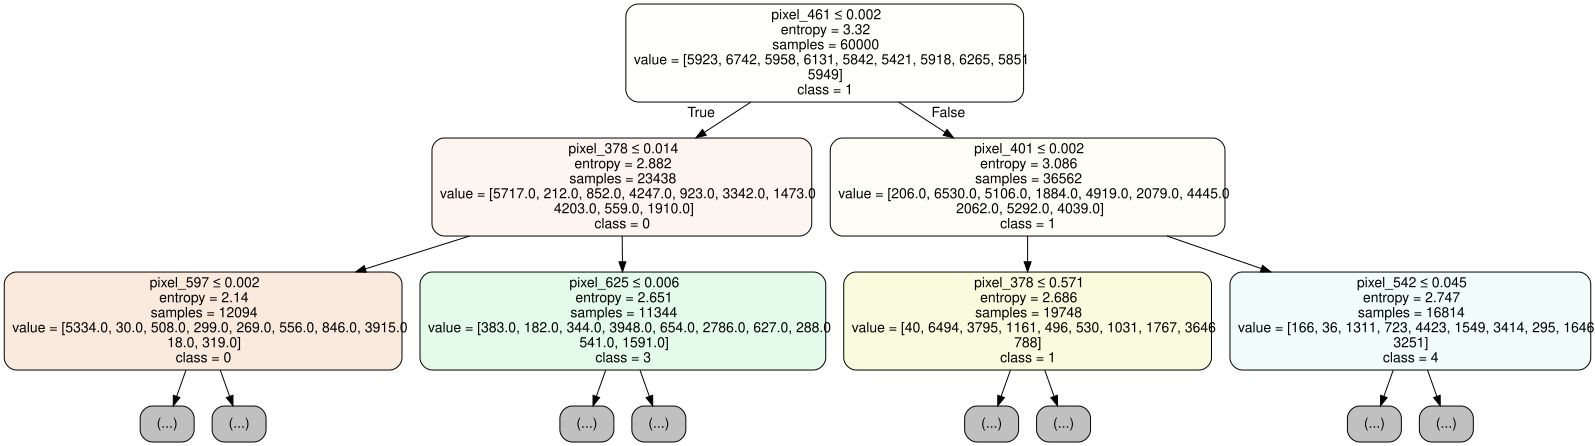

In [ ]:
# Ausschnitt des gelernten Decision Trees

feature_names = [f"pixel_{i}" for i in range(X_train.shape[1])]
class_names = [str(i) for i in range(10)]

dot_data = export_graphviz(
    final_clf,
    out_file=None,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    special_characters=True,
    max_depth=2
)

graph = graphviz.Source(dot_data)
graph

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


mean_scores = []

for Iteration in [100, 120, 130, 140]:
    logreg = LogisticRegression(
        C= 0.1,
        solver="lbfgs",
        max_iter= Iteration,
        random_state=42
    )

    scores = cross_val_score(
        logreg,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    mean_scores.append(scores.mean())
    print(f"Max Iteration ={Iteration}: CV-Accuracy={scores.mean():.4f}")

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://sciki

Max Iteration =100: CV-Accuracy=0.9216


/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 120 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=120).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 120 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=120).
You might also want to scale the data as shown in:
    https://sciki

Max Iteration =120: CV-Accuracy=0.9214
Max Iteration =130: CV-Accuracy=0.9215
Max Iteration =140: CV-Accuracy=0.9215


In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score

for depth in [7,8,9]:
    for n_estimators in [500,600,700]:
            clf = AdaBoostClassifier(
                estimator=DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=42
                ),
                n_estimators=n_estimators,
                learning_rate= 0.5,
                random_state=42
            )

            clf.fit(X_train, y_train)
            y_pred = clf.predict(X_test)
            acc = accuracy_score(y_test, y_pred)

            print(
                f"depth={depth}, n_estimators={n_estimators}, "
                f"-> acc={acc:.4f}"
            )

depth=7, n_estimators=500, -> acc=0.9748
depth=7, n_estimators=600, -> acc=0.9742
depth=7, n_estimators=700, -> acc=0.9752
depth=8, n_estimators=500, -> acc=0.9762
depth=8, n_estimators=600, -> acc=0.9766
depth=8, n_estimators=700, -> acc=0.9760


KeyboardInterrupt: 

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
import pandas as pd

# ----------------------------
# kleineres, stratifiziertes Trainingssubset
# ----------------------------
X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,
    stratify=y_train,
    random_state=42
)

print("Subset shape:", X_train_small.shape, y_train_small.shape)

# ----------------------------
# Cross-Validation
# ----------------------------
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

results = []

# ----------------------------
# Hyperparameter-Schleifen
# ----------------------------
for depth in [5, 6, 7, 8]:
    for n_estimators in [300, 400, 500, 600, 700, 800]:
        for learning_rate in [0.3, 0.5, 1.0]:

            clf = AdaBoostClassifier(
                estimator=DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=42
                ),
                n_estimators=n_estimators,
                learning_rate=learning_rate,
                random_state=42
            )

            scores = cross_val_score(
                clf,
                X_train_small,
                y_train_small,
                cv=cv,
                scoring="accuracy",
                n_jobs=-1
            )

            mean_acc = scores.mean()

            results.append({
                "depth": depth,
                "n_estimators": n_estimators,
                "learning_rate": learning_rate,
                "cv_accuracy": mean_acc
            })

            print(
                f"depth={depth}, "
                f"n_estimators={n_estimators}, "
                f"learning_rate={learning_rate} "
                f"-> CV-Accuracy={mean_acc:.4f}"
            )

results_df = pd.DataFrame(results).sort_values("cv_accuracy", ascending=False)

print("\nBeste Kombinationen auf dem Trainingssubset:")
print(results_df.head(10))

Subset shape: (10000, 784) (10000,)
depth=5, n_estimators=300, learning_rate=0.3 -> CV-Accuracy=0.9338
depth=5, n_estimators=300, learning_rate=0.5 -> CV-Accuracy=0.9317
depth=5, n_estimators=300, learning_rate=1.0 -> CV-Accuracy=0.9249
depth=5, n_estimators=400, learning_rate=0.3 -> CV-Accuracy=0.9364
depth=5, n_estimators=400, learning_rate=0.5 -> CV-Accuracy=0.9337
depth=5, n_estimators=400, learning_rate=1.0 -> CV-Accuracy=0.9249
depth=5, n_estimators=500, learning_rate=0.3 -> CV-Accuracy=0.9384
depth=5, n_estimators=500, learning_rate=0.5 -> CV-Accuracy=0.9339
depth=5, n_estimators=500, learning_rate=1.0 -> CV-Accuracy=0.9269
depth=5, n_estimators=600, learning_rate=0.3 -> CV-Accuracy=0.9386
depth=5, n_estimators=600, learning_rate=0.5 -> CV-Accuracy=0.9356
depth=5, n_estimators=600, learning_rate=1.0 -> CV-Accuracy=0.9265
depth=5, n_estimators=700, learning_rate=0.3 -> CV-Accuracy=0.9392
depth=5, n_estimators=700, learning_rate=0.5 -> CV-Accuracy=0.9361
depth=5, n_estimators=700,

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score

# Basisbaum für AdaBoost
base_tree = DecisionTreeClassifier(
    max_depth=8,
    random_state=42
)

# AdaBoost-Modell
ada_clf = AdaBoostClassifier(
    estimator=base_tree,
    n_estimators= 700,
    learning_rate=0.3,
    random_state=42
)

# Training
ada_clf.fit(X_train, y_train)

# Vorhersage auf dem Testset
y_pred_ada = ada_clf.predict(X_test)

# Accuracy berechnen
test_acc_ada = accuracy_score(y_test, y_pred_ada)

print("AdaBoost Test Accuracy:", test_acc_ada)

AdaBoost Test Accuracy: 0.9768


In [6]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd
import time



estimators = [
    ("boosted_tree", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=9,
            random_state=42
        ),
        n_estimators= 500,
        learning_rate=0.3,
        random_state=42
    )),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(
        max_depth=20,
        n_estimators=150,
        random_state=208
    )),

]

stack_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=100),
    stack_method="predict_proba",
    passthrough = True, 
    cv=3,
    n_jobs=-1
)

stack_clf.fit(X_train, y_train)

y_pred_stack = stack_clf.predict(X_test)
stack_acc = accuracy_score(y_test, y_pred_stack)

print("Stacking Accuracy:", stack_acc)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Stacking Accuracy: 0.9811


In [7]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd
import time



estimators = [
    ("boosted_tree", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=9,
            random_state=42
        ),
        n_estimators= 500,
        learning_rate=0.3,
        random_state=42
    )),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(
        max_depth=20,
        n_estimators=150,
        random_state=208
    )),

]

stack_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=100),
    stack_method="predict_proba",
    passthrough = True, 
    cv=5,
    n_jobs=-1
)

stack_clf.fit(X_train, y_train)

y_pred_stack = stack_clf.predict(X_test)
stack_acc = accuracy_score(y_test, y_pred_stack)

print("Stacking Accuracy:", stack_acc)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Stacking Accuracy: 0.9802


In [ ]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd
import time



estimators = [
    ("boosted_tree", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=9,
            random_state=42
        ),
        n_estimators= 700,
        learning_rate=0.3,
        random_state=42
    )),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
    ("rf", RandomForestClassifier(
        max_depth=20,
        n_estimators=150,
        random_state=208
    )),

]

stack_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(
        max_iter= 80 , 
        C = 10.0,
        solver="lbfgs",
        penalty="l2",
        random_state=42),
    stack_method="predict_proba",
    passthrough = True, 
    cv=5,
    n_jobs=-1
)

stack_clf.fit(X_train, y_train)

y_pred_stack = stack_clf.predict(X_test)
stack_acc = accuracy_score(y_test, y_pred_stack)

print("Stacking Accuracy:", stack_acc)

/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/lenovo/Dokumente/python-projekt/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 80 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=80).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regre

Stacking Accuracy: 0.9795
